In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
df = pd.read_csv('data_sus2.csv', encoding='latin1', sep=';')
df.head()

,estado,2008/Jan,2008/Fev,2008/Mar,2008/Abr,2008/Mai,2008/Jun,2008/Jul,2008/Ago,2008/Set,...,2025/Dez,2026/Jan,2026/Fev,2026/Mar,2026/Abr,2026/Mai,2026/Jun,2026/Jul,2026/Ago,Total
0,11 RondÃ´nia,4142,7301,4318,4285,4511,3871,7560,7615,7507,...,11527,11520,11425,13535,12441,12024,10245,9798,8817,2097068
1,12 Acre,2087,3071,3783,3737,3609,4026,4880,4250,4552,...,4527,4774,4479,5088,4951,5328,4997,5053,-,937020
2,13 Amazonas,9325,12754,14780,14556,12833,14073,15430,15660,15061,...,21768,21748,20400,23276,23452,23457,22860,23077,20180,3506049
3,14 Roraima,1475,1812,1813,1964,2037,2030,2307,2153,1913,...,2128,2597,2961,3082,3013,3199,3936,515,-,682210
4,15 ParÃ¡,38628,41530,42790,41112,44643,43506,45110,43661,44256,...,48817,47347,45674,51283,50366,49924,48089,47572,44143,9396155


In [22]:
def corrigir_estado(valor):
    estados = {
        '11': '11 Rondônia', '12': '12 Acre', '13': '13 Amazonas',
        '14': '14 Roraima', '15': '15 Pará', '16': '16 Amapá',
        '17': '17 Tocantins', '21': '21 Maranhão', '22': '22 Piauí',
        '23': '23 Ceará', '24': '24 Rio Grande do Norte',
        '25': '25 Paraíba', '26': '26 Pernambuco', '27': '27 Alagoas',
        '28': '28 Sergipe', '29': '29 Bahia', '31': '31 Minas Gerais',
        '32': '32 Espírito Santo', '33': '33 Rio de Janeiro',
        '35': '35 São Paulo', '41': '41 Paraná',
        '42': '42 Santa Catarina', '43': '43 Rio Grande do Sul',
        '50': '50 Mato Grosso do Sul', '51': '51 Mato Grosso',
        '52': '52 Goiás', '53': '53 Distrito Federal'
    }
    if pd.isna(valor):
        return valor
    codigo = str(valor).strip().split(maxsplit=1)[0]
    return estados.get(codigo, valor)

df['estado'] = df['estado'].apply(corrigir_estado)
df[['estado']].head()

,estado
0,11 Rondônia
1,12 Acre
2,13 Amazonas
3,14 Roraima
4,15 Pará


In [23]:
df.head()

,estado,2008/Jan,2008/Fev,2008/Mar,2008/Abr,2008/Mai,2008/Jun,2008/Jul,2008/Ago,2008/Set,...,2025/Dez,2026/Jan,2026/Fev,2026/Mar,2026/Abr,2026/Mai,2026/Jun,2026/Jul,2026/Ago,Total
0,11 Rondônia,4142,7301,4318,4285,4511,3871,7560,7615,7507,...,11527,11520,11425,13535,12441,12024,10245,9798,8817,2097068
1,12 Acre,2087,3071,3783,3737,3609,4026,4880,4250,4552,...,4527,4774,4479,5088,4951,5328,4997,5053,-,937020
2,13 Amazonas,9325,12754,14780,14556,12833,14073,15430,15660,15061,...,21768,21748,20400,23276,23452,23457,22860,23077,20180,3506049
3,14 Roraima,1475,1812,1813,1964,2037,2030,2307,2153,1913,...,2128,2597,2961,3082,3013,3199,3936,515,-,682210
4,15 Pará,38628,41530,42790,41112,44643,43506,45110,43661,44256,...,48817,47347,45674,51283,50366,49924,48089,47572,44143,9396155


In [27]:
df.shape

(28, 226)

In [24]:
# Converte as colunas mensais em linhas e exclui apenas a coluna de total geral.
df_mensal = df.melt(
    id_vars='estado',
    value_vars=[coluna for coluna in df.columns if coluna not in ('estado', 'Total')],
    var_name='data',
    value_name='valor'
)

meses = {
    'Jan': '01', 'Fev': '02', 'Mar': '03', 'Abr': '04',
    'Mai': '05', 'Jun': '06', 'Jul': '07', 'Ago': '08',
    'Set': '09', 'Out': '10', 'Nov': '11', 'Dez': '12'
}
ano_mes = df_mensal['data'].str.split('/')
df_mensal['data'] = pd.to_datetime(
    ano_mes.str[0] + '-' + ano_mes.str[1].map(meses) + '-01'
)

df_mensal.head()

,estado,data,valor
0,11 Rondônia,2008-01-01,4142
1,12 Acre,2008-01-01,2087
2,13 Amazonas,2008-01-01,9325
3,14 Roraima,2008-01-01,1475
4,15 Pará,2008-01-01,38628


In [25]:
df.estado.unique()

array(['11 Rondônia', '12 Acre', '13 Amazonas', '14 Roraima', '15 Pará',
       '16 Amapá', '17 Tocantins', '21 Maranhão', '22 Piauí', '23 Ceará',
       '24 Rio Grande do Norte', '25 Paraíba', '26 Pernambuco',
       '27 Alagoas', '28 Sergipe', '29 Bahia', '31 Minas Gerais',
       '32 Espírito Santo', '33 Rio de Janeiro', '35 São Paulo',
       '41 Paraná', '42 Santa Catarina', '43 Rio Grande do Sul',
       '50 Mato Grosso do Sul', '51 Mato Grosso', '52 Goiás',
       '53 Distrito Federal', 'Total'], dtype=object)

<Axes: xlabel='data', ylabel='valor'>

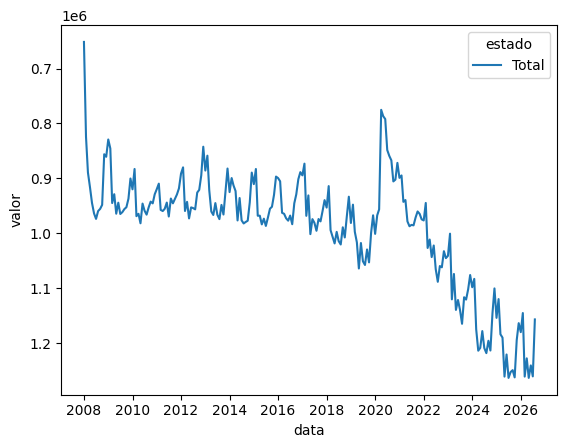

In [26]:
sns.lineplot(data=df_mensal[df_mensal.estado == 'Total'], x='data', y='valor', hue='estado')